# 05 · Data Visualization
**Mục tiêu:** Trực quan hóa 
**bằng chứng** cho kết quả phân tích ở bước 4, không lặp lại Cleaning.  
**Đơn vị:** 1 item, target `freight_value`. **Mỗi biểu đồ:** Câu hỏi → Hình → Cách đọc.

## 5.1. Setup & Source

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
from pathlib import Path
import pandas as pd

# Dung du lieu da lam sach cua buoc 2 neu co. Khong sua file goc.
DATA_DIR = None
for path in [Path('../data'), Path('data'), Path('../../data')]:
    if (path / 'cleaned' / 'olist_clean.csv').exists() or (path / 'raw' / 'olist_order_items_dataset.csv').exists():
        DATA_DIR = path
        break

if DATA_DIR is None:
    raise FileNotFoundError('Khong thay data/cleaned/olist_clean.csv hoac data/raw/*.csv. Mo notebook trong notebooks/ cua repo.')

CLEAN_FILE = DATA_DIR / 'cleaned' / 'olist_clean.csv'
if CLEAN_FILE.exists():
    df = pd.read_csv(CLEAN_FILE)
    source = 'CLEANED (step 2)'
else:
    # Fallback de notebook van chay truoc khi nhom xuat du lieu clean.
    raw = DATA_DIR / 'raw'
    items = pd.read_csv(raw / 'olist_order_items_dataset.csv')
    orders = pd.read_csv(raw / 'olist_orders_dataset.csv',
                         usecols=['order_id','customer_id','order_status','order_purchase_timestamp'])
    customers = pd.read_csv(raw / 'olist_customers_dataset.csv',
                            usecols=['customer_id','customer_state'])
    products = pd.read_csv(raw / 'olist_products_dataset.csv',
                           usecols=['product_id','product_category_name','product_weight_g',
                                    'product_length_cm','product_height_cm','product_width_cm'])
    sellers = pd.read_csv(raw / 'olist_sellers_dataset.csv',
                          usecols=['seller_id','seller_state'])
    translation = pd.read_csv(raw / 'product_category_name_translation.csv')

    df = items.merge(orders, on='order_id', how='left', validate='m:1')
    df = df.merge(customers, on='customer_id', how='left', validate='m:1')
    df = df.merge(products, on='product_id', how='left', validate='m:1')
    df = df.merge(sellers, on='seller_id', how='left', validate='m:1')
    df = df.merge(translation, on='product_category_name', how='left', validate='m:1')
    source = 'RAW fallback (chua ap dung rule cleaning cua buoc 2)'

# Chuan hoa TEN COT chi trong RAM (neu buoc 2 dat ten ngan hon).
aliases = {
    'c_state': 'customer_state', 's_state': 'seller_state',
    'category': 'product_category_name',
    'category_english': 'product_category_name_english',
}
for old, new in aliases.items():
    if new not in df.columns and old in df.columns:
        df = df.rename(columns={old: new})

# Cot thoi gian: neu buoc 2 chua giu lai, lay them tu RAW (1 order -> 1 timestamp).
if 'order_purchase_timestamp' not in df.columns:
    orders_file = DATA_DIR / 'raw' / 'olist_orders_dataset.csv'
    if orders_file.exists():
        orders_time = pd.read_csv(orders_file,
                                  usecols=['order_id','order_purchase_timestamp'])
        df = df.merge(orders_time, on='order_id', how='left', validate='m:1')

required = ['order_id','order_item_id','freight_value','price','seller_id']
missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f'Du lieu khong dung schema item-level, thieu cot: {missing}')

print('SOURCE:', source)
print('ROWS / COLS:', df.shape)
print('GRAIN: (order_id, order_item_id) | TARGET: freight_value')

SOURCE: CLEANED (step 2)
ROWS / COLS: (108937, 27)
GRAIN: (order_id, order_item_id) | TARGET: freight_value


In [15]:
# Cac cot phuc vu EDA; khong phai preprocessing cho model.
if all(col in df.columns for col in ['product_length_cm','product_height_cm','product_width_cm']):
    df['volume_cm3'] = (df['product_length_cm'] *
                        df['product_height_cm'] * df['product_width_cm'])

if 'customer_state' in df.columns and 'seller_state' in df.columns:
    valid = df['customer_state'].notna() & df['seller_state'].notna()
    df['same_state'] = pd.NA
    df.loc[valid, 'same_state'] = (df.loc[valid, 'customer_state'] ==
                                   df.loc[valid, 'seller_state'])

if 'product_category_name_english' in df.columns:
    df['category_eda'] = df['product_category_name_english']
    if 'product_category_name' in df.columns:
        df['category_eda'] = df['category_eda'].fillna(df['product_category_name'])
elif 'product_category_name' in df.columns:
    df['category_eda'] = df['product_category_name']

if 'order_purchase_timestamp' in df.columns:
    df['purchase_date'] = pd.to_datetime(df['order_purchase_timestamp'], errors='coerce')
    df['purchase_month'] = df['purchase_date'].dt.to_period('M')

print('EDA columns:', [c for c in ['volume_cm3','same_state','category_eda','purchase_month'] if c in df.columns])

EDA columns: ['volume_cm3', 'same_state', 'category_eda', 'purchase_month']


## 5.2. Histogram — Freight tập trung ở khoảng nào?
**Câu hỏi:** Phí ship có lệch phải và đuôi dài không? `xlim` dùng để xem rõ 99% phía dưới, **không loại item**.

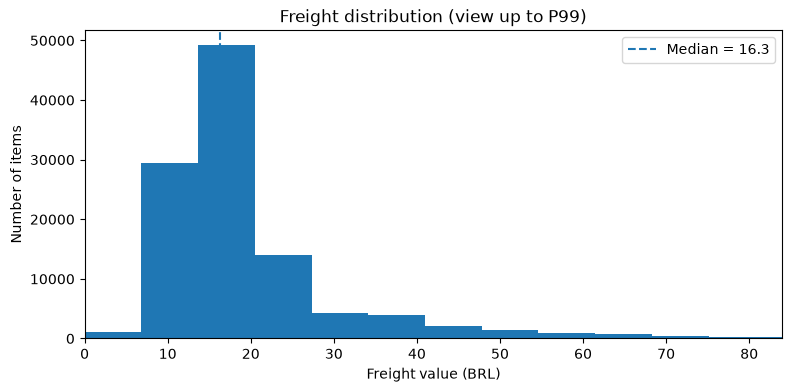

Mean=20.01; Median=16.28; P99=83.96


In [16]:
s = pd.to_numeric(df['freight_value'], errors='coerce').dropna()
plt.figure(figsize=(9,4))
plt.hist(s, bins=60)
plt.axvline(s.median(), linestyle='--', label=f'Median = {s.median():.1f}')
plt.xlim(0, s.quantile(.99))
plt.xlabel('Freight value (BRL)')
plt.ylabel('Number of items')
plt.title('Freight distribution (view up to P99)')
plt.legend()
plt.show()
print(f'Mean={s.mean():.2f}; Median={s.median():.2f}; P99={s.quantile(.99):.2f}')

**Nhận xét đúng:** Nếu đuôi hướng phải, ghi *“phân phối lệch phải”*. Không nói “lỗi” chỉ vì phí cao.

## 5.3. Boxplot — phân tán và điểm cực trị
**Câu hỏi:** Giá trị trung tâm, IQR và ngưỡng trên khác nhau như thế nào? `showfliers=False` chỉ **ẩn chấm**, không xóa dữ liệu.

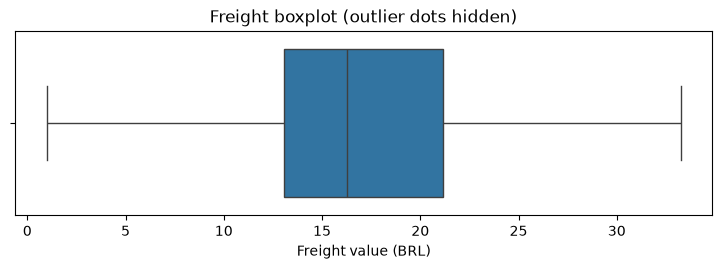

Q1=13.08; Median=16.28; Q3=21.15; IQR=8.07
IQR outliers=11,349 (10.42%) | Khong tu dong xoa.


In [17]:
q1, q3 = s.quantile([.25,.75])
iqr = q3-q1
upper = q3 + 1.5*iqr
flag = (s < q1-1.5*iqr) | (s > upper)
plt.figure(figsize=(9,2.4))
sns.boxplot(x=s, showfliers=False)
plt.xlabel('Freight value (BRL)')
plt.title('Freight boxplot (outlier dots hidden)')
plt.show()
print(f'Q1={q1:.2f}; Median={s.median():.2f}; Q3={q3:.2f}; IQR={iqr:.2f}')
print(f'IQR outliers={flag.sum():,} ({100*flag.mean():.2f}%) | Khong tu dong xoa.')

## 5.4. Scatter — Price và Freight có đi cùng nhau?
**Câu hỏi:** Quan hệ giữa 2 biến có rõ ràng không? Để biểu đồ đọc được, chỉ **lấy mẫu chấm**; hệ số tương quan vẫn tính trên **toàn bộ dữ liệu**.

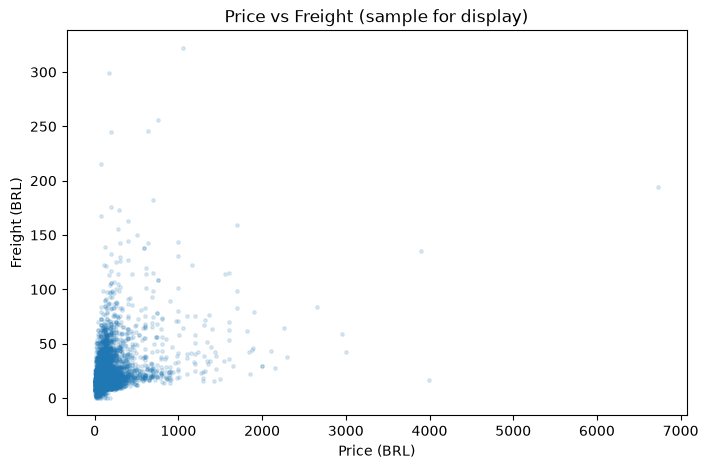

Full-data Pearson: 0.414
Full-data Spearman: 0.438


In [18]:
points = df[['price','freight_value']].dropna()
view = points.sample(n=min(10000, len(points)), random_state=42)
plt.figure(figsize=(8,5))
plt.scatter(view['price'], view['freight_value'], alpha=.15, s=6)
plt.xlabel('Price (BRL)')
plt.ylabel('Freight (BRL)')
plt.title('Price vs Freight (sample for display)')
plt.show()
print('Full-data Pearson:', round(points['price'].corr(points['freight_value']), 3))
print('Full-data Spearman:', round(points['price'].corr(points['freight_value'],method='spearman'),3))

**Cách đọc:** Các điểm có xu hướng lên → có liên hệ dương; đám mây tản rộng → quan hệ không chặt. **Correlation ≠ causation.**

## 5.5. Heatmap — biến nào liên hệ với target?
**Câu hỏi:** `price`, `product_weight_g` và `volume_cm3` có quan hệ tuyến tính với phí ship không?

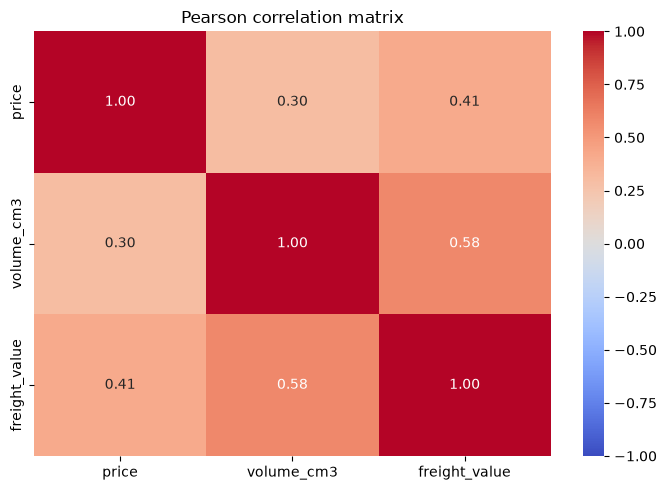

In [19]:
cols = [col for col in ['price','product_weight_g','volume_cm3','freight_value'] if col in df.columns]
corr = df[cols].corr()
plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Pearson correlation matrix')
plt.tight_layout()
plt.show()

**Cách đọc:** gần +1 / −1 = quan hệ tuyến tính mạnh cùng / ngược chiều; gần 0 = tuyến tính yếu. Đây **không phải** kiểm tra nhân quả.

## 5.6. Countplot — seller nào có nhiều items?
**Câu hỏi:** Top 5 seller theo **số item**, không phải số đơn và cũng không phải phí cao.

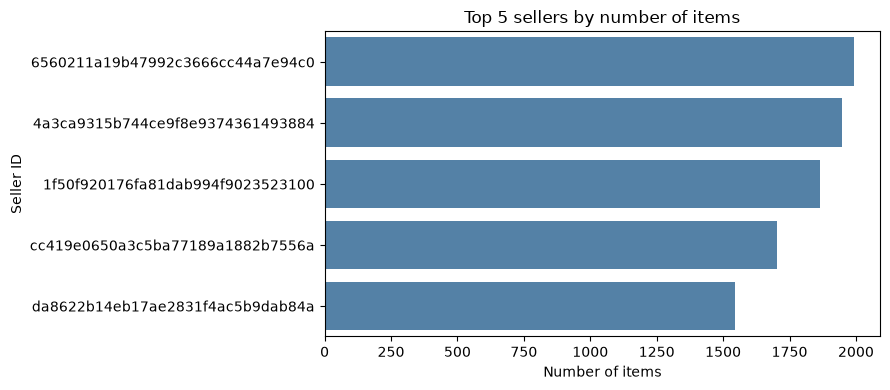

In [20]:
top5 = df['seller_id'].value_counts().head(5).index
sub = df[df['seller_id'].isin(top5)]
plt.figure(figsize=(9,4))
sns.countplot(data=sub, y='seller_id', order=top5, color='steelblue')
plt.title('Top 5 sellers by number of items')
plt.xlabel('Number of items')
plt.ylabel('Seller ID')
plt.tight_layout()
plt.show()

## 5.7. Grouped Boxplot — freight của top seller có khác nhau?
**Câu hỏi:** Median/IQR theo seller có giống nhau không? Top được chọn theo **tần suất**, tránh chọn theo trung bình rồi kết luận thiên lệch.

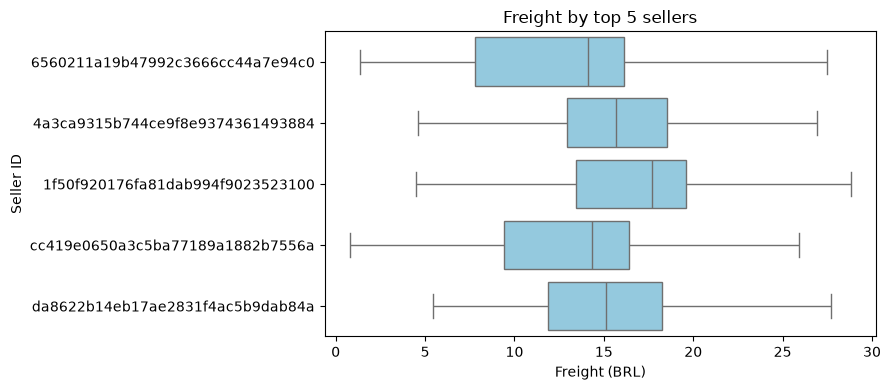

,size,mean,median
seller_id,,,
6560211a19b47992c3666cc44a7e94c0,1991,13.70,14.10
4a3ca9315b744ce9f8e9374361493884,1947,17.61,15.70
1f50f920176fa81dab994f9023523100,1865,18.75,17.67
cc419e0650a3c5ba77189a1882b7556a,1704,14.45,14.34
da8622b14eb17ae2831f4ac5b9dab84a,1546,16.07,15.10


In [21]:
plt.figure(figsize=(9,4))
sns.boxplot(data=sub, x='freight_value', y='seller_id', order=top5, showfliers=False, color='skyblue')
plt.title('Freight by top 5 sellers')
plt.xlabel('Freight (BRL)')
plt.ylabel('Seller ID')
plt.tight_layout()
plt.show()
display(sub.groupby('seller_id')['freight_value']
        .agg(['size','mean','median']).loc[top5].round(2))

**Cách đọc:** Vạch giữa = median, bề rộng hộp = IQR. Đừng kết luận seller “tăng phí ship” vì seller còn bán loại hàng/vị trí giao khác nhau.

## 5.8. Barplot — category nào có median freight cao?
**Câu hỏi:** Trong những category có **ít nhất 100 items**, nhóm nào có median cao? Có ngưỡng số mẫu để tránh nhóm quá hiếm.

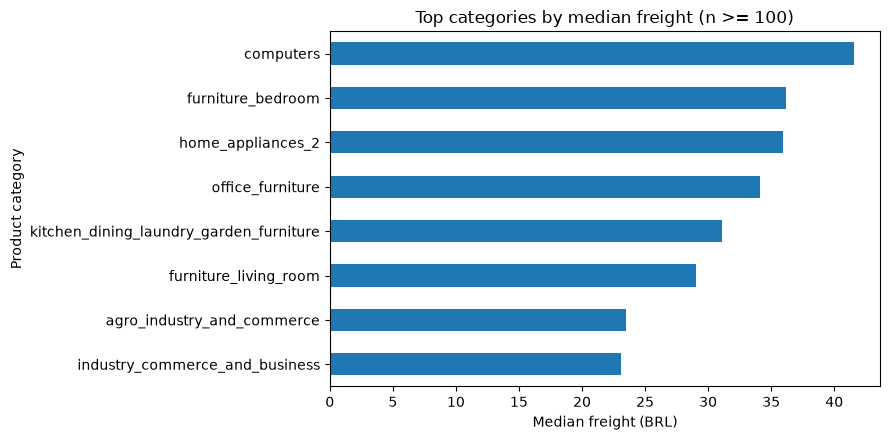

,size,median
category_eda,,
computers,198,41.55
furniture_bedroom,103,36.18
home_appliances_2,230,35.90
office_furniture,1655,34.12
kitchen_dining_laundry_garden_furniture,273,31.10
furniture_living_room,443,29.04
agro_industry_and_commerce,206,23.50
industry_commerce_and_business,260,23.09


In [22]:
if 'category_eda' in df.columns:
    cat = df.groupby('category_eda')['freight_value'].agg(['size','median'])
    cat = cat.loc[cat['size'] >= 100].sort_values('median', ascending=False).head(8)
    plt.figure(figsize=(9,4.5))
    cat.sort_values('median')['median'].plot(kind='barh')
    plt.xlabel('Median freight (BRL)')
    plt.ylabel('Product category')
    plt.title('Top categories by median freight (n >= 100)')
    plt.tight_layout()
    plt.show()
    display(cat.round(2))
else:
    print('Category khong co trong file clean; bo qua chart nay.')

**Cách đọc:** Đây là **median phí ship** (không phải số lượng hay tổng doanh thu). Sự khác nhau có thể đến từ weight/size/vị trí, chưa đủ cơ sở để quy nguyên nhân cho category.

## 5.9. Same State — cùng bang có mức freight khác không?
**Câu hỏi:** Có chênh lệch giữa các items cùng bang người bán–người mua và khác bang? Không coi *cùng bang* là **khoảng cách thực**.

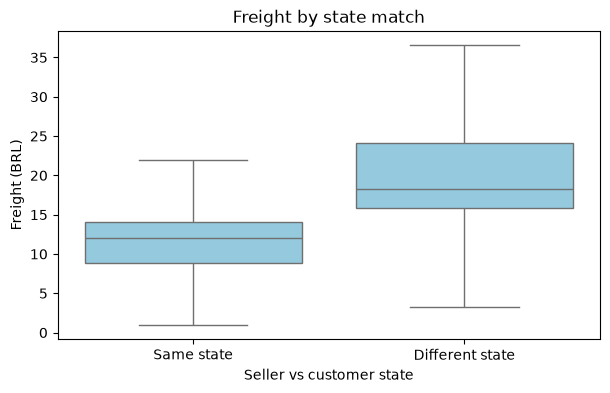

,size,mean,median
route_group,,,
Different state,69330,23.74,18.26
Same state,39607,13.48,12.03


In [23]:
if 'same_state' in df.columns:
    state_view = df.dropna(subset=['same_state']).copy()
    state_view['route_group'] = state_view['same_state'].map({True:'Same state', False:'Different state'})
    plt.figure(figsize=(7,4))
    sns.boxplot(data=state_view, x='route_group', y='freight_value',
                order=['Same state','Different state'], showfliers=False, color='skyblue')
    plt.xlabel('Seller vs customer state')
    plt.ylabel('Freight (BRL)')
    plt.title('Freight by state match')
    plt.show()
    display(state_view.groupby('route_group')['freight_value']
            .agg(['size','mean','median']).round(2))
else:
    print('Thieu customer_state / seller_state; bo qua chart nay.')

## 5.10. Line — phí ship theo tháng
**Câu hỏi:** Mức trung bình có biến đổi theo thời gian? Luôn xem **số items** theo tháng trước khi kết luận có xu hướng.

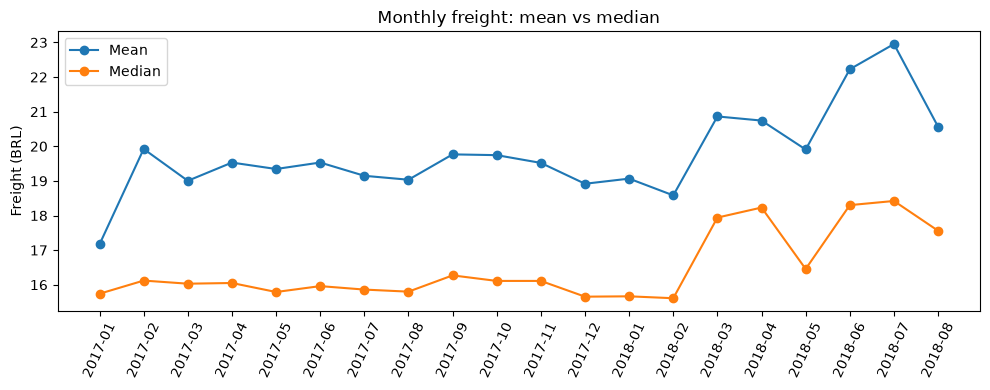

,size,mean,median
purchase_month,,,
2018-01,7998,19.07,15.66
2018-02,7478,18.58,15.61
2018-03,7981,20.86,17.94
2018-04,7634,20.74,18.23
2018-05,7558,19.91,16.45
2018-06,6981,22.23,18.30
2018-07,6934,22.95,18.42
2018-08,7105,20.57,17.56


In [24]:
if 'purchase_month' in df.columns:
    monthly = (df.dropna(subset=['purchase_month'])
               .groupby('purchase_month')['freight_value']
               .agg(['size','mean','median']))
    if not monthly.empty:
        monthly.index = monthly.index.astype(str)
        plt.figure(figsize=(10,4))
        plt.plot(monthly.index, monthly['mean'], marker='o', label='Mean')
        plt.plot(monthly.index, monthly['median'], marker='o', label='Median')
        plt.xticks(rotation=65)
        plt.ylabel('Freight (BRL)')
        plt.title('Monthly freight: mean vs median')
        plt.legend()
        plt.tight_layout()
        plt.show()
        display(monthly.tail(8).round(2))
else:
    print('Khong co ngay mua; bo qua chart theo thang.')

## 5.11. Evidence-based Conclusion
1. **Distribution:** Dùng **Histogram + Boxplot** để kết luận hình dạng và độ phân tán; báo `median`, `IQR`, tỷ lệ outliers.
2. **Relationships:** Dùng **Scatter + Heatmap** để nói về *mức độ liên hệ*, không kết luận nguyên nhân.
3. **Segments:** Dùng **Countplot + Barplot + Grouped Boxplot** để so nhóm, luôn ghi **size**.
4. **Time & geography:** Chỉ đưa ra nhận xét sau khi xem phân phối, số mẫu và các yếu tố nhiễu.

**Handoff → Step 6:** Đề xuất các biến *biết trước lúc giao* như giá, kích thước, trọng lượng, địa lý; **không sử dụng** thông tin giao hàng thực tế sau thời điểm dự đoán hoặc biến tính trực tiếp từ target. Nếu phát hiện nghi vấn, **ghi về bước 2 để kiểm tra**, không xóa trong EDA.

